# 第2回講義 演習

今回は，深層モデルやそのライブラリは用いず，機械学習の基礎を理解するために，まず回帰問題を扱い，その後ロジスティック回帰およびソフトマックス回帰を実装します．

なお，ロジスティック回帰やソフトマックス回帰は名前に「回帰」とありますが，分類問題であることに注意してください．シグモイド関数を用いることで，データのラベルが1または0である確率を出力します．


## 目次

1. [【課題 1】回帰問題と平均二乗誤差 (MSE)](#scrollTo=t4lVHe-VtcDY&line=5&uniqifier=1)

    1.1. [データセットの作成]()

    1.2. [モデル・損失関数・学習方法]()

    1.3. [学習前の予測]()

    1.4. [学習]()

    1.5. [学習結果の確認]()

1. [【課題 2】ロジスティック回帰の実装と学習 (OR)](#scrollTo=quBPRwBf4Kq7&line=1&uniqifier=1)
    
    2.1. [シグモイド関数](#scrollTo=awSlFgRA4Kq9)

    2.2. [データセットの設定と重みの定義](#scrollTo=HAA-lvhz4KrF)
    
    2.3. [train関数とvalid関数](#scrollTo=7raMb3ts4KrL)
    
    2.4. [学習](#scrollTo=LiuO_6B-4Krb)

1. [【課題 3】ソフトマックス回帰の実装と学習 (MNIST)](#scrollTo=44tdPsW34Krq&line=1&uniqifier=1)
    
    3.1. [ソフトマックス関数](#scrollTo=YEprLDMd4Krr)
    
    3.2. [データセットの設定と重みの定義](#scrollTo=52fR-55x4Krx)
    
    3.3. [train関数とvalid関数](#scrollTo=80EOFI-n4Kr6)

    3.4. [学習](#scrollTo=JBGInXhG4KsJ)


In [1]:
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from keras.datasets import mnist
import matplotlib.pyplot as plt

import numpy as np

np.random.seed(34)

## 1.【課題 1】回帰問題と平均二乗誤差 (MSE)

まず最も基本的な例として，連続値を予測する回帰問題を考える．  
ここでは，ニューラルネットワークの学習の基本構造を，  
平均二乗誤差 (Mean Squared Error; MSE)を用いて確認する．


### 1.1. データセットの作成

1次元入力 $x$ に対して，連続値 $y$ を出力する回帰データを作成する．  
ここでは，ノイズを含む線形関数を用いる．


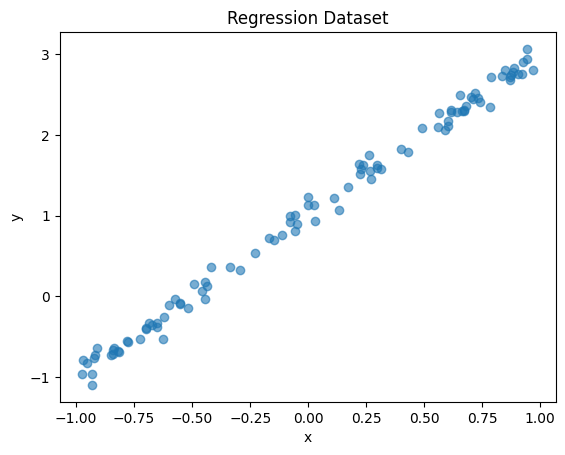

In [2]:
# データ数
N = 100

# 入力
x = np.random.uniform(-1, 1, (N, 1))

# 正解値（線形 + ノイズ）
y = 2 * x + 1 + 0.1 * np.random.randn(N, 1)

# 可視化
plt.scatter(x, y, alpha=0.6)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Regression Dataset")
plt.show()


### 1.2. モデル・損失関数・学習方法

回帰問題では，入力 $x$ から出力 $\hat{y}$ を予測するモデルを学習する．  
ここでは最も単純なニューラルネットワークとして，線形変換を用いる．

$\hat{y} = Wx + b$

モデルの学習には，予測値と正解値の差を測る  
平均二乗誤差 (Mean Squared Error; MSE)を用いる．

$\mathrm{MSE} = \frac{1}{N}\sum_{i=1}^N (y_i - \hat{y}_i)^2$

勾配降下法により，MSE を最小化するように  
パラメータ $W, b$ を更新する．


In [3]:
# パラメータの初期化
W = np.random.randn(1, 1)
b = np.zeros((1,))

# 平均二乗誤差
def mse(y, y_hat):
    return np.mean((y - y_hat) ** 2)

# 学習関数
def train(x, y, W, b, lr=0.1):
    # 予測
    y_hat = x @ W + b

    # 損失
    loss = mse(y, y_hat)

    # 勾配の計算
    dW = 2 * np.mean((y_hat - y) * x)
    db = 2 * np.mean(y_hat - y)

    # パラメータの更新
    W -= lr * dW
    b -= lr * db

    return W, b, loss


### 1.3. 学習前の予測

初期化直後のパラメータ $W, b$ を用いた予測を可視化する．  
この時点では，モデルはまだデータの構造を学習していない．


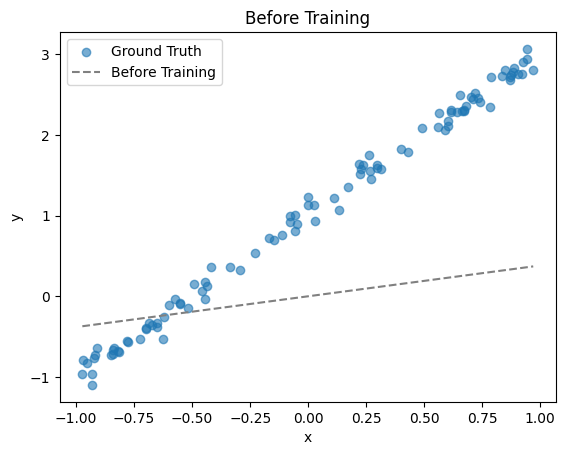

In [4]:
# 学習前の予測
y_pred_init = x @ W + b

# 入力 x をソート
idx = np.argsort(x[:, 0])
x_sorted = x[idx]
y_pred_init_sorted = y_pred_init[idx]

plt.scatter(x, y, alpha=0.6, label="Ground Truth")
plt.plot(x_sorted, y_pred_init_sorted, color="gray", linestyle="--", label="Before Training")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Before Training")
plt.legend()
plt.show()


### 1.4. 学習

勾配降下法によりパラメータを更新し，MSE が減少することを確認する．


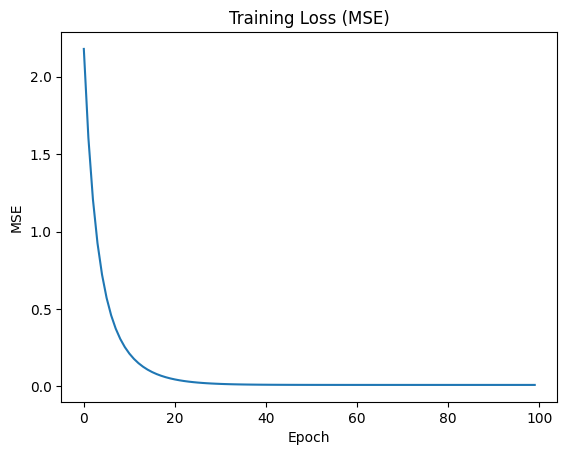

W: [2.00677778]
b: [1.01537154]


In [5]:
epochs = 100
lr = 0.1
losses = []

for epoch in range(epochs):
    W, b, loss = train(x, y, W, b, lr=lr)
    losses.append(loss)

plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Training Loss (MSE)")
plt.show()

print("W:", W.ravel())
print("b:", b)


### 1.5. 学習結果の確認

学習後のモデルが，入力 $x$ に対してどのような予測 $\hat{y}$ を出すかを可視化する．


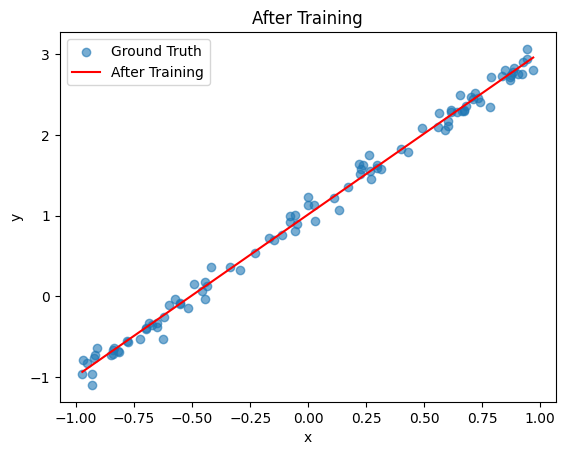

In [6]:
# 学習後の予測
y_pred = x @ W + b

# 線を描きやすくするため入力 x をソート
idx = np.argsort(x[:, 0])
x_sorted = x[idx]
y_pred_sorted = y_pred[idx]

plt.scatter(x, y, alpha=0.6, label="Ground Truth")
plt.plot(x_sorted, y_pred_sorted, color="red", label="After Training")
plt.xlabel("x")
plt.ylabel("y")
plt.title("After Training")
plt.legend()
plt.show()


## 2.【課題 2】ロジスティック回帰の実装と学習 (OR)

### 2.1. シグモイド関数
$$
    \sigma({\bf x}) = \frac{1}{1 + \exp(-{\bf x})} = \frac{\exp({\bf x})}{1 + \exp({\bf x})}
$$

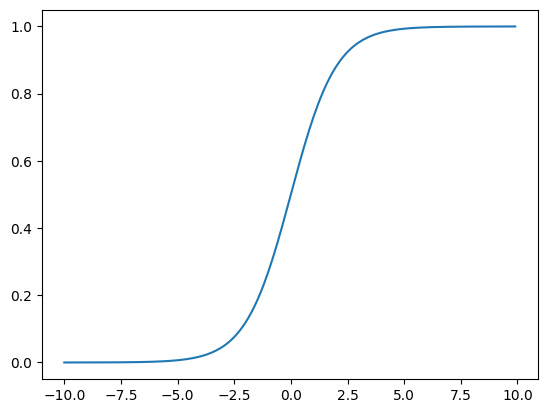

In [7]:
def sigmoid(x):
    # 単純な実装
    # return 1 / (1 + np.exp(-x))

    # expのoverflow対策を施した実装
    # x >=0 のとき sigmoid(x) = 1 / (1 + exp(-x))
    # x < 0 のとき sigmoid(x) = exp(x) / (1 + exp(x))
    return np.exp(np.minimum(x, 0)) / (1 + np.exp(- np.abs(x))) # WRITE ME

x = np.arange(-10, 10, 0.1)
plt.plot(x, sigmoid(x.copy()))

### 2.2. データセットの設定と重みの定義

次にデータセットと，パラメータの初期化を行います．

今回扱うORゲートは，二つの入力の少なくともどちらかが1であれば1を出力し，入力が両方とも0であれば0を出力します．

これが線形な分類器で実現可能な問題であることは，下図からもわかります．

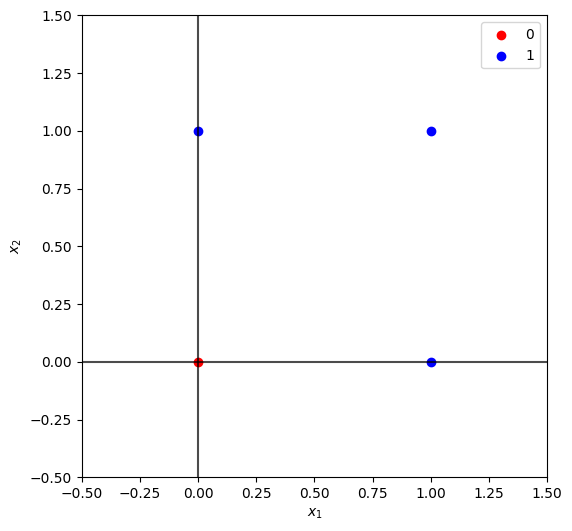

In [8]:
# ORのデータセット
x_train_or = np.array([[0, 1], [1, 0], [0, 0], [1, 1]])  # (4, 2)
y_train_or = np.array([[1], [1], [0], [1]])              # (4, 1)
x_valid_or, y_valid_or = x_train_or, y_train_or
# x_test_or, y_test_or = x_train_or, y_train_or

plt.figure(figsize=(6, 6))
plt.hlines([0], xmin=-1, xmax=2, color="black", alpha=0.7)
plt.vlines([0], ymin=-1, ymax=2, color="black", alpha=0.7)

plt.scatter(*x_train_or[y_train_or.squeeze() == 0].T, color="red", label="0")
plt.scatter(*x_train_or[y_train_or.squeeze() == 1].T, color="blue", label="1")

plt.xlabel(r"$x_1$")
plt.ylabel(r"$x_2$")
plt.xlim([-0.5, 1.5])
plt.ylim([-0.5, 1.5])
plt.legend()
plt.show()

次にパラメータを初期化します．重みは一様分布からのサンプリング，バイアスは0で初期化を行います．

In [9]:
# 重み（入力層の次元数: 2，出力層の次元数: 1）
W_or = np.random.uniform(low=-0.08, high=0.08, size=(2, 1)).astype('float32')
b_or = np.zeros(shape=(1,)).astype('float32')

### 2.3. train関数とvalid関数

**目的関数**

2クラス交差エントロピー誤差関数
$$ E ({\bf x}, {\bf y}; {\bf W}, {\bf b} ) =  -\frac{1}{N}\sum^N_{i=1} \left[ {\bf y}_i \log {\bf \hat{y}}_i ({\bf x}_i; {\bf W}, {\bf b}) + (1 - {\bf y}_i) \log \{ 1 - {\bf \hat{y}}_i ({\bf x}_i; {\bf W}, {\bf b}) \}\right] $$

**モデルの推論**
$$
    {\bf \hat{y}}_i = \sigma({\bf W}^T {\bf x}_i + {\bf b})
$$

**モデルの学習**

勾配降下法により学習します．クロスエントロピー誤差関数 $E$ のパラメータに関する勾配は以下のように簡単に計算できるので，それに基づいて更新を行っていきます．

\begin{align*}
    \delta_i &= {\bf \hat{y}}_i - {\bf y}_i \\
    \nabla_{\bf W} E &= \frac{1}{N}\sum^N_{i=1}\delta_i {\bf x}^{\mathrm{T}}_i \\
    \nabla_{\bf b} E &= \frac{1}{N}\sum^N_{i=1}\delta_i  \\
    {\bf W} &\leftarrow {\bf W} - \epsilon \nabla_{\bf W} E \\
    {\bf b} &\leftarrow {\bf b} - \epsilon \nabla_{\bf b} E \\
\end{align*}

In [10]:
# logの中身が0になるのを防ぐ
def np_log(x):
    return np.log(np.clip(a=x, a_min=1e-10, a_max=1e+10))

In [11]:
def train_or(x, y, eps=1.0):
    """
    :param x: np.ndarray, 入力データ, (batch_size, 入力の次元数)
    :param y: np.ndarray, 教師ラベル, (batch_size, 出力の次元数)
    :param eps: float, 学習率
    """
    global W_or, b_or

    batch_size = x.shape[0]

    # 予測
    y_hat = sigmoid(np.matmul(x, W_or) + b_or)  # (batch_size, 出力の次元数)

    # 目的関数の評価
    cost = (- y * np_log(y_hat) - (1 - y) * np_log(1 - y_hat)).mean() # WRITE ME
    delta = y_hat - y  # (batch_size, 出力の次元数)

    # パラメータの更新
    dW = np.matmul(x.T, delta) / batch_size  # (入力の次元数, 出力の次元数)
    db = np.matmul(np.ones(shape=(batch_size,)), delta) / batch_size  # (出力の次元数,)
    W_or -= eps * dW
    b_or -= eps * db

    return cost

def valid_or(x, y):
    y_hat = sigmoid(np.matmul(x, W_or) + b_or)
    cost = (- y * np_log(y_hat) - (1 - y) * np_log(1 - y_hat)).mean()
    return cost, y_hat

### 2.4. 学習

In [12]:
for epoch in range(1000):
    # x_train_or, y_train_or = shuffle(x_train_or, y_train_or)
    cost = train_or(x_train_or, y_train_or)
    cost, y_pred = valid_or(x_valid_or, y_valid_or)

print(y_pred)

[[0.99181364]
 [0.9918129 ]
 [0.02049799]
 [0.99999857]]


## 3.【課題 3】ソフトマックス回帰の実装と学習 (MNIST)

ソフトマックス回帰は，ロジスティック回帰を多クラス分類に拡張したものです．

### 3.1. ソフトマックス関数

ソフトマックス関数は分子の全クラスにわたる和が分母になるので，モデルの出力を確率分布（多項分布）に直すものと考えることができます．

$$
\mathrm{softmax}({\bf x})_k
= \frac{\exp({\bf x}_k)}{\sum^K_{k'=1} \exp({\bf x}_{k'})}
= \frac{\exp({\bf x}_k - m)}{\sum^K_{k'=1} \exp({\bf x}_{k'} - m)} \hspace{10mm} \text{for} \, k=1,\ldots, K
$$

ソフトマックス関数は入力に対して定数を足し引きしても結果が変わりません．上式では，定数 $m = \max^K_{i=1} x_i$ を入力から引くことで，指数を取った時に値がオーバーフローしてしまうのを防ぐための実装を行っています．

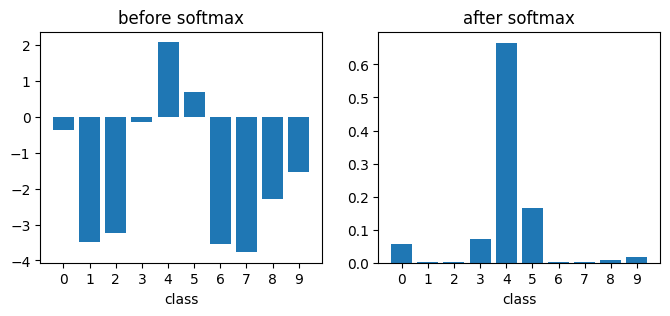

In [13]:
def softmax(x, axis=1):
    x -= x.max(axis, keepdims=True)   # WRITE ME# expのoverflowを防ぐ
    x_exp = np.exp(x) # WRITE ME
    return x_exp / x_exp.sum(axis, keepdims=True) # WRITE ME

x = np.random.uniform(-5, 5, (1, 10))
y = softmax(x.copy())
fig, axs = plt.subplots(ncols=2, figsize=(8, 3))
for i, (d, title) in enumerate(zip([x, y], ['before', 'after'])):
    axs[i].bar(np.arange(10), d.squeeze())
    axs[i].set_title(f"{title} softmax")
    axs[i].set_xticks(np.arange(10))
    axs[i].set_xlabel("class")

$K=2$（2クラス）の際のソフトマックス関数を可視化してみます．

Text(0.5, 0.5, 'x_2')

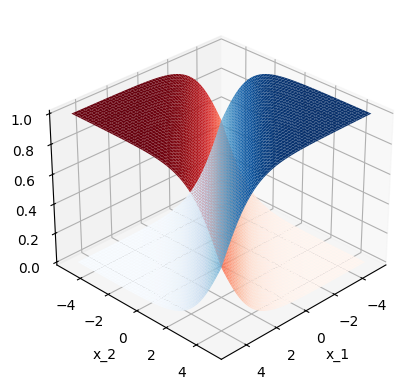

In [14]:
x = np.stack(np.meshgrid(
    np.arange(-5, 5, 0.1),
    np.arange(-5, 5, 0.1)
))
y = softmax(x.copy(), axis=0)

ax = plt.axes(projection='3d')
ax.view_init(elev=30, azim=45)
ax.plot_surface(x[0], x[1], y[0], cmap='Reds')
ax.plot_surface(x[0], x[1], y[1], cmap='Blues')
ax.set_xlabel("x_1")
ax.set_ylabel("x_2")

### 3.2. データセットの設定と重みの定義

次にデータセットを作成します．ここでは画像の多クラス分類タスクとして知られるMNISTデータセットを用います．MNISTデータセットは0-9の手書き文字の画像入力とし，画像にどの数字が書かれているかを出力する10クラス分類のタスクです．入力データは以下のようなグレースケールの画像が入力されます．

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


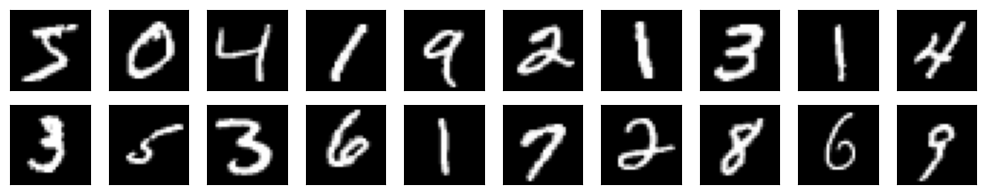

In [15]:
(x_mnist_1, y_mnist_1), (x_mnist_2, y_mnist_2) = mnist.load_data()

x_mnist = np.r_[x_mnist_1, x_mnist_2]
y_mnist = np.r_[y_mnist_1, y_mnist_2]

fig = plt.figure(figsize=(10, 10))

for i in range(20):
    x = x_mnist[i]
    ax = fig.add_subplot(10, 10, i+1, xticks=[], yticks=[])
    ax.imshow(x, 'gray')
fig.tight_layout(rect=[0,0,1,0.96])
plt.show()

In [16]:
x_mnist = x_mnist.astype('float32') / 255.  # 画素値のスケーリング: 0 - 255 (整数) → 0.0 - 1.0 (浮動小数点数)
y_mnist = np.eye(N=10)[y_mnist.astype('int32').flatten()]  # 整数ラベル (0–9) を one-hot ベクトル に変換

x_mnist=x_mnist.reshape(x_mnist.shape[0],-1)  # 画素の平坦化: 28 * 28 (2次元画像) → 784 (1次元画像)

x_train_mnist, x_test_mnist, y_train_mnist, y_test_mnist = train_test_split(x_mnist, y_mnist, test_size=10000)
x_train_mnist, x_valid_mnist, y_train_mnist, y_valid_mnist = train_test_split(x_train_mnist, y_train_mnist, test_size=10000)

In [17]:
W_mnist = np.random.uniform(low=-0.08, high=0.08, size=(784, 10)).astype('float32')  # 重み: (784, 10)
b_mnist = np.zeros(shape=(10,)).astype('float32')

### 3.3. train関数とvalid関数

**目的関数**

多クラス交差エントロピー誤差関数
$$ E ({\bf x}, {\bf y}; {\bf W}, {\bf b} ) =  -\frac{1}{N}\sum^N_{i=1} \sum^K_{k=1} {\bf y}_{i, k} \log {\bf \hat{y}}_{i, k} ({\bf x}_i; {\bf W}, {\bf b}) $$

**モデルの推論**
$$
    {\bf \hat{y}}_i = \mathrm{softmax}({\bf W}^T{\bf x}_i + {\bf b})
$$

**モデルの学習**
\begin{align*}
    \delta_i &= {\bf \hat{y}}_i - {\bf y}_i \\
    \nabla_{\bf W} E &= \frac{1}{N}\sum^N_{i=1}x_i {\bf \delta}^{\mathrm{T}}_i \\
    \nabla_{\bf b} E &= \frac{1}{N}\sum^N_{i=1}\delta_i  \\
    {\bf W} &\leftarrow {\bf W} - \epsilon \nabla_{\bf W} E \\
    {\bf b} &\leftarrow {\bf b} - \epsilon \nabla_{\bf b} E \\
\end{align*}

In [18]:
def train_mnist(x, y, eps=1.0):
    """
    :param x: np.ndarray, 入力データ, (batch_size, 入力の次元数)
    :param y: np.ndarray, 教師ラベル, (batch_size, 出力の次元数)
    :param eps: float, 学習率
    """
    global W_mnist, b_mnist

    batch_size = x.shape[0]

    # 予測
    y_hat = softmax(np.matmul(x, W_mnist) + b_mnist)  # (batch_size, 出力の次元数)

    # 目的関数の評価
    cost = (- y * np_log(y_hat)).sum(axis=1).mean()
    delta = y_hat - y  # (batch_size, 出力の次元数)

    # パラメータの更新
    dW = np.matmul(x.T, delta) / batch_size  # (入力の次元数, 出力の次元数)
    db = np.matmul(np.ones(shape=(batch_size,)), delta) / batch_size  # (出力の次元数,)
    W_mnist -= eps * dW
    b_mnist -= eps * db

    return cost

def valid_mnist(x, y):
    y_hat = softmax(np.matmul(x, W_mnist) + b_mnist)
    cost = (- y * np_log(y_hat)).sum(axis=1).mean()

    return cost, y_hat

### 3.4. 学習

In [19]:
for epoch in range(100):
    cost = train_mnist(x_train_mnist, y_train_mnist)

    cost, y_pred = valid_mnist(x_valid_mnist, y_valid_mnist)
    if epoch % 10 == 9 or epoch == 0:
        print('EPOCH: {}, Valid Cost: {:.3f}, Valid Accuracy: {:.3f}'.format(
            epoch + 1,
            cost,
            accuracy_score(y_valid_mnist.argmax(axis=1), y_pred.argmax(axis=1))
        ))

EPOCH: 1, Valid Cost: 1.743, Valid Accuracy: 0.401
EPOCH: 10, Valid Cost: 0.922, Valid Accuracy: 0.744
EPOCH: 20, Valid Cost: 0.518, Valid Accuracy: 0.838
EPOCH: 30, Valid Cost: 0.478, Valid Accuracy: 0.858
EPOCH: 40, Valid Cost: 0.411, Valid Accuracy: 0.887
EPOCH: 50, Valid Cost: 0.381, Valid Accuracy: 0.898
EPOCH: 60, Valid Cost: 0.369, Valid Accuracy: 0.902
EPOCH: 70, Valid Cost: 0.360, Valid Accuracy: 0.904
EPOCH: 80, Valid Cost: 0.353, Valid Accuracy: 0.905
EPOCH: 90, Valid Cost: 0.347, Valid Accuracy: 0.907
EPOCH: 100, Valid Cost: 0.342, Valid Accuracy: 0.907
